In [6]:
import numpy as np
import pandas as pd
import joblib

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

best_model = joblib.load("best_model.pkl")
X_test = joblib.load("X_test.pkl")
y_test = joblib.load("y_test.pkl")

y_prob = best_model.predict_proba(X_test)[:,1]

thresholds = np.arange(0.10, 0.91, 0.10)

results = []

for threshold in thresholds:
    y_pred = (y_prob >= threshold).astype(int)

    results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_test, y_pred, zero_division=0
        )
    })

threshold_df = pd.DataFrame(results)
display(threshold_df)


,Threshold,Precision,Recall,F1
0,0.1,0.282634,0.908817,0.431176
1,0.2,0.412460,0.683497,0.514464
2,0.3,0.516878,0.553881,0.534740
3,0.4,0.592195,0.457423,0.516156
4,0.5,0.649457,0.360211,0.463403
5,0.6,0.705996,0.275057,0.395879
6,0.7,0.776892,0.146948,0.247148
7,0.8,0.873239,0.046722,0.088698
8,0.9,0.947368,0.013564,0.026746


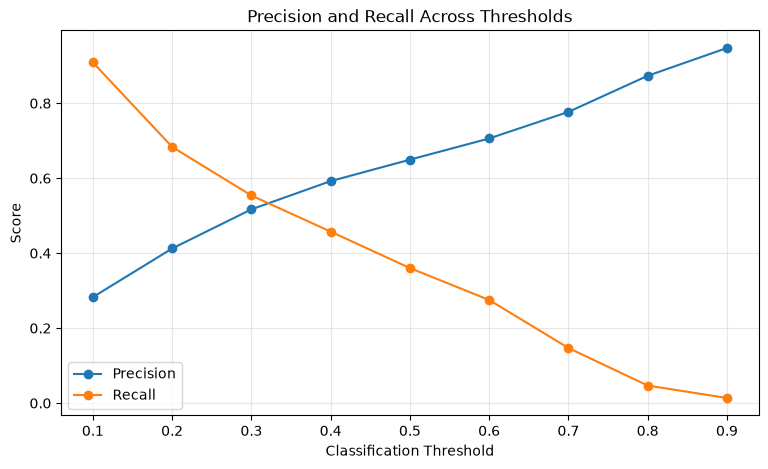

In [7]:
# Step 2 — Plot the precision–recall trade-off

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision and Recall Across Thresholds")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


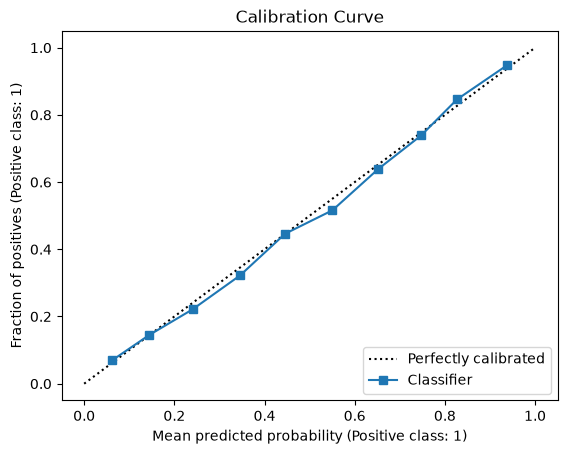

Brier Score: 0.1362


In [8]:
# Step 3 — Check probability calibration

from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import brier_score_loss

CalibrationDisplay.from_predictions(
    y_test,
    y_prob,
    n_bins=10
)

plt.title("Calibration Curve")
plt.show()

print(
    "Brier Score:",
    round(brier_score_loss(y_test, y_prob), 4)
)
